# Proyecto Integrador — Parte I (EC2)
## Tasación de viviendas con Machine Learning · Dataset **Ames Housing**

**Asignatura:** SIS-351 Machine Learning · **Metodología:** CRISP-DM · **Instancia:** Competencia 2 (EC2)

**Propósito (según la guía):** demostrar que el equipo puede *formular, preparar, modelar, comparar e interpretar* una solución de ML con evidencia reproducible, antes de avanzar a Deep Learning, MLOps y recuperación semántica (Parte II).

| Fase CRISP-DM | Sección del notebook |
|---|---|
| 1. Comprensión del problema | 3.1 |
| 2. Comprensión de los datos | 3.2 |
| 3. Preparación de datos | 3.3 |
| 4. Modelado (supervisado, no supervisado, AutoML) | 3.4 – 3.6 |
| 5. Evaluación (métricas y análisis de errores) | 3.7 |
| 6. Despliegue | Fuera del EC2 → Parte II (solo se deja el plan) |

**Alcance EC2 — qué NO se hace aquí** (diapositiva "Alcance"): Deep Learning completo (MLP, autoencoder), embeddings como núcleo, índice vectorial, pipeline MLOps ni demo. Se dejan preparados los artefactos para la Parte II.

## 0. Configuración y reproducibilidad
Todas las rutas, semillas y parámetros del experimento se definen aquí y se guardan en `config/experiment_config.json`.

In [24]:
import json, time, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error, silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---- Rutas (estructura mínima del repositorio pedida en la guía) ----
ROOT = Path(".").resolve()
if ROOT.name == "notebooks":          # el notebook vive en /notebooks; los artefactos van a la raíz del repo
    ROOT = ROOT.parent
DATA_DIR, MODELS_DIR, REPORTS_DIR, CONFIG_DIR = (ROOT / d for d in ["data", "models", "reports", "config"])
FIG_DIR = REPORTS_DIR / "figures"
for d in [DATA_DIR, MODELS_DIR, REPORTS_DIR, CONFIG_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "seed": 42,
    "data_file": "AmesHousing.csv",
    "target": "SalePrice",
    "test_size": 0.20,
    "val_size_of_rest": 0.25,      # 0.25 * 0.80 = 20 % del total -> 60/20/20
    "cv_folds": 5,
    "outlier_rule": "Gr Liv Area > 4000 (recomendación De Cock, 2011)",
    "excluded_columns": ["Order", "PID", "Sale Type", "Sale Condition"],
    "automl_tool": "FLAML",
    "automl_time_budget_s": 120,
}
SEED = CONFIG["seed"]
np.random.seed(SEED)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("Python", platform.python_version(), "| sklearn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.13.16 | sklearn 1.6.1 | pandas 2.2.3


# 3.1 Comprensión del problema
> **Pregunta guía:** ¿Qué problema real resolvemos y cómo sabremos que lo logramos?

**Contexto y necesidad.** En el mercado inmobiliario la tasación de una vivienda se hace con frecuencia de forma manual (agente o perito comparando "propiedades similares"). Es lenta, subjetiva y difícil de auditar. Compradores, vendedores, bancos (crédito hipotecario) y municipios (avalúo fiscal) necesitan una **estimación de precio rápida, consistente y explicable**.

**Problema formulado (para un usuario real).** *"Dadas las características físicas, de ubicación y de calidad de una vivienda en Ames (Iowa), ¿cuál es su precio de venta esperado y qué tan confiable es esa estimación?"*

**Objetivo y variable objetivo.**
- Tarea: **regresión supervisada**.
- Target: `SalePrice` (USD). Se modela `log(1 + SalePrice)` porque el error relevante para una tasación es **relativo** (equivocarse en 20 000 USD es grave en una casa de 80 000, no tanto en una de 500 000) y la distribución es asimétrica.

**Criterios de éxito (definidos antes de modelar).**

| Criterio | Medida | Umbral de éxito |
|---|---|---|
| Rendimiento | RMSE en escala log (≈ error relativo) sobre test | < 0.13 y al menos 30 % mejor que el baseline B1 |
| Utilidad | MAPE en USD | < 10 % (rango habitual de diferencia aceptado en tasaciones) |
| Interpretabilidad | Poder explicar qué variables mueven el precio | Importancias / coeficientes coherentes con el dominio |
| Factibilidad | Entrenamiento en CPU de laptop | < 5 min por modelo |

**Restricciones y riesgos.** Datos de una sola ciudad y periodo 2006-2010 (incluye la crisis de 2008) → generalización geográfica y temporal limitada; pocos registros (≈2 900) para modelos muy complejos; posibles ventas atípicas (ventas parciales, entre familiares); sesgo hacia viviendas unifamiliares típicas.

# 3.2 Comprensión de los datos
### Fuente y variante
- **Origen:** De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project.* Journal of Statistics Education 19(3). Datos de la oficina de avalúo de Ames, ventas 2006–2010.
- **Variante usada:** versión **completa** (2 930 registros, 80 variables explicativas + identificadores + target). Espejos: OpenML / Kaggle (`shashanknecrothapa/ames-housing-dataset`).
- ⚠️ No confundir con la competencia de Kaggle *House Prices* (1 460 filas): es **un subconjunto** del mismo dataset. Usamos la versión completa porque tiene el doble de datos.
- **Fecha de acceso:** 2026-10-21. Archivo en `data/AmesHousing.csv`.

### Subconjunto y muestreo
Se usa el dataset completo; solo se excluyen 5 viviendas de más de 4 000 ft² que el propio autor recomienda retirar (ventas parciales/atípicas). No se submuestrea.

In [25]:
path = DATA_DIR / CONFIG["data_file"]
if not path.exists():   # p. ej. en Colab: se descarga la misma copia que está en el repo
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/AlanMC7650/EC2_Ames_Housing/main/data/AmesHousing.csv", path)
assert path.exists(), f"Falta {path}. Descarga AmesHousing.csv (ver data/README.md) y colócalo en /data."
df_raw = pd.read_csv(path)
df_raw = df_raw.loc[:, ~df_raw.columns.str.startswith("Unnamed")]   # algunas copias traen el índice guardado
print("Forma:", df_raw.shape)
df_raw.head()

Forma: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,...,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,...,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,...,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,...,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,...,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,...,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [26]:
# Tabla de variables (tipo, % faltantes, nº de valores únicos, ejemplo)
var_table = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "%_nulos": (df_raw.isna().mean() * 100).round(1),
    "n_unicos": df_raw.nunique(),
    "ejemplo": df_raw.iloc[0],
}).sort_values("%_nulos", ascending=False)
var_table.to_csv(REPORTS_DIR / "tabla_variables.csv")
n_num = df_raw.select_dtypes("number").shape[1]; n_cat = df_raw.select_dtypes(exclude="number").shape[1]
print(f"Numéricas: {n_num} | Categóricas: {n_cat}")
var_table.head(15)

Numéricas: 39 | Categóricas: 43


,dtype,%_nulos,n_unicos,ejemplo
Pool QC,object,99.6,4,NaN
Misc Feature,object,96.4,5,NaN
Alley,object,93.2,2,NaN
Fence,object,80.5,4,NaN
Mas Vnr Type,object,60.6,4,Stone
Fireplace Qu,object,48.5,5,Gd
Lot Frontage,float64,16.7,128,141.0
Garage Type,object,5.4,6,Attchd
Garage Qual,object,5.4,5,TA
Garage Finish,object,5.4,3,Fin


**Variables principales y su significado** (grupos del diccionario de De Cock):

| Grupo | Ejemplos | Significado |
|---|---|---|
| Tamaño | `Gr Liv Area`, `Total Bsmt SF`, `1st/2nd Flr SF`, `Lot Area`, `Garage Area` | Superficies en pies² |
| Calidad / estado | `Overall Qual`, `Overall Cond`, `Exter Qual`, `Kitchen Qual`, `Bsmt Qual` | Escalas ordinales (1–10 o Po→Ex) |
| Antigüedad | `Year Built`, `Year Remod/Add`, `Yr Sold`, `Mo Sold` | Año de construcción, remodelación y venta |
| Ubicación | `Neighborhood`, `MS Zoning`, `Condition 1/2` | Barrio, zonificación, proximidad a vías/tren |
| Equipamiento | `Full Bath`, `Fireplaces`, `Garage Cars`, `Central Air`, `Pool Area` | Comodidades |
| Venta | `Sale Type`, `Sale Condition` | Tipo de contrato y condición de la venta |
| Identificadores | `Order`, `PID` | Sin valor predictivo |

### Diagnóstico de calidad

Duplicados exactos: 0
PID duplicados: 0


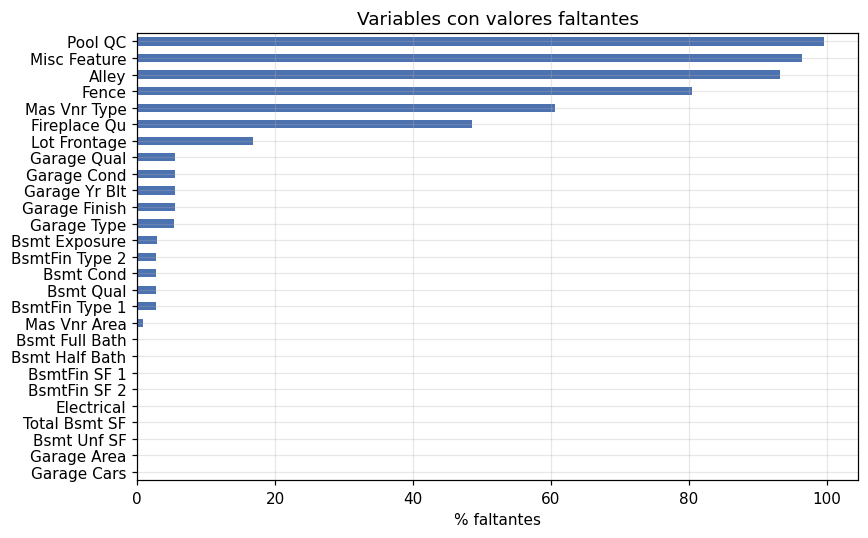

In [27]:
print("Duplicados exactos:", df_raw.duplicated().sum())
print("PID duplicados:", df_raw["PID"].duplicated().sum())
nulls = df_raw.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
(nulls / len(df_raw) * 100).plot.barh(ax=ax, color="#4C72B0"); ax.invert_yaxis()
ax.set_xlabel("% faltantes"); ax.set_title("Variables con valores faltantes")
savefig("01_faltantes"); plt.show()

**Interpretación.** La mayoría de los "faltantes" **no son datos perdidos**: según el diccionario, `NA` en `Pool QC`, `Misc Feature`, `Alley`, `Fence`, `Fireplace Qu`, `Garage *`, `Bsmt *` significa **"la casa no tiene esa característica"**. Imputarlos con la moda sería un error conceptual → se imputan como categoría `"None"` (o 0 en las escalas ordinales). Solo `Lot Frontage` (~17 %) y unos pocos campos numéricos tienen faltantes reales → mediana, ajustada **solo en train**.

### EDA interpretado

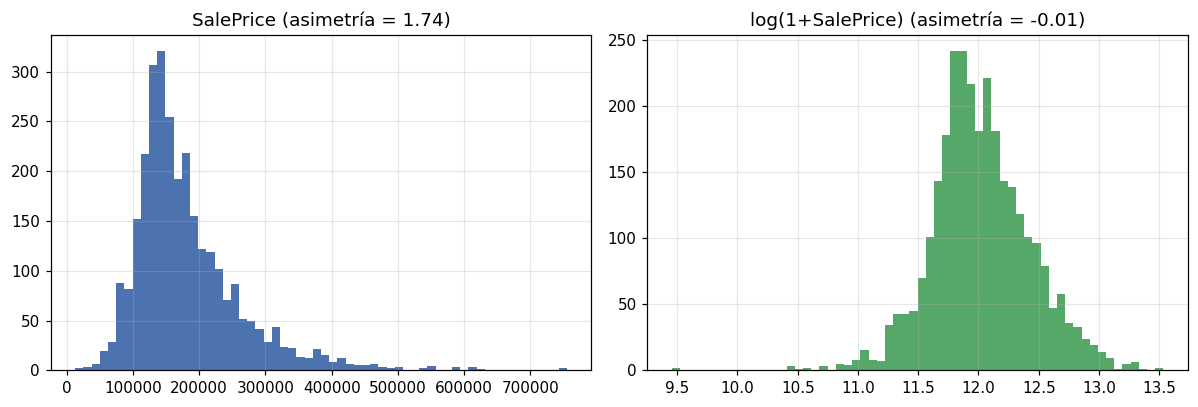

,SalePrice
count,2930.0
mean,180796.0
std,79887.0
min,12789.0
25%,129500.0
50%,160000.0
75%,213500.0
max,755000.0


In [28]:
y_raw = df_raw["SalePrice"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(y_raw, bins=60, color="#4C72B0"); axes[0].set_title(f"SalePrice (asimetría = {y_raw.skew():.2f})")
axes[1].hist(np.log1p(y_raw), bins=60, color="#55A868"); axes[1].set_title(f"log(1+SalePrice) (asimetría = {np.log1p(y_raw).skew():.2f})")
savefig("02_target"); plt.show()
y_raw.describe().round(0)

**Hallazgo 1 — target asimétrico.** El precio tiene cola larga a la derecha; tras `log1p` queda casi simétrico. **Decisión:** modelar en escala logarítmica con `TransformedTargetRegressor` (la transformación es determinista, no aprende nada de los datos → no hay fuga) y usar RMSE en log como métrica principal.

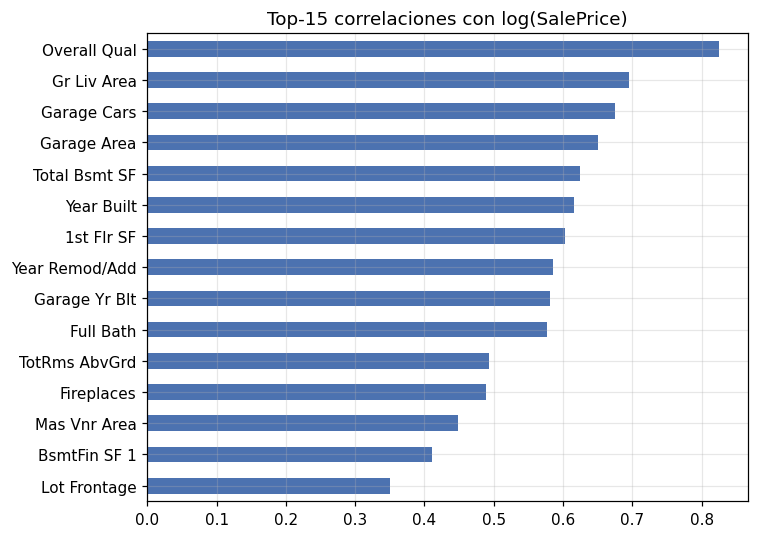

,0
Overall Qual,0.826
Gr Liv Area,0.696
Garage Cars,0.675
Garage Area,0.651
Total Bsmt SF,0.625
Year Built,0.615
1st Flr SF,0.603
Year Remod/Add,0.586
Garage Yr Blt,0.581
Full Bath,0.577


In [29]:
num_cols_raw = df_raw.select_dtypes("number").columns.drop(["Order", "PID", "SalePrice"])
corr = df_raw[num_cols_raw].corrwith(np.log1p(y_raw)).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
corr.head(15)[::-1].plot.barh(ax=ax, color="#4C72B0"); ax.set_title("Top-15 correlaciones con log(SalePrice)")
savefig("03_correlaciones"); plt.show()
corr.head(10).round(3)

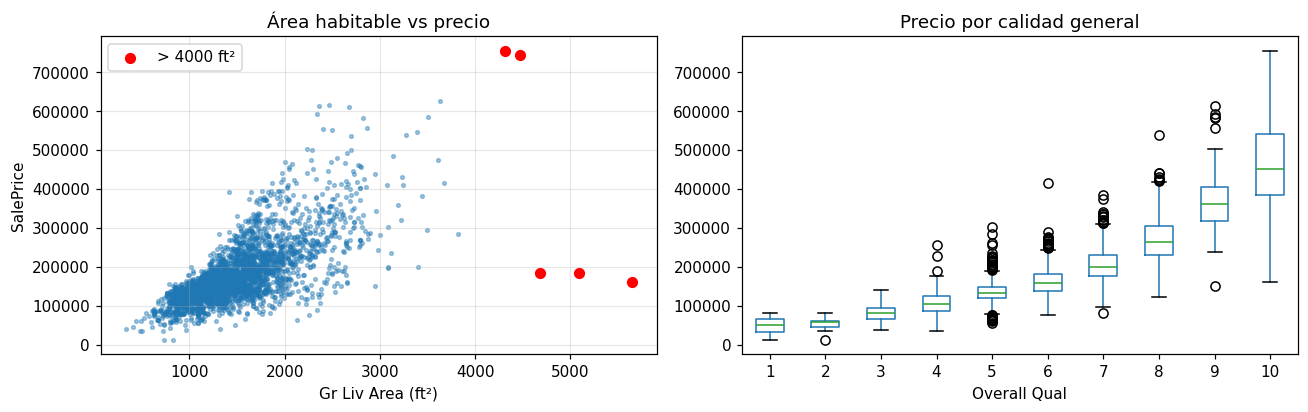

      Gr Liv Area  SalePrice Sale Condition
1498         5642     160000        Partial
1760         4476     745000        Abnorml
1767         4316     755000         Normal
2180         5095     183850        Partial
2181         4676     184750        Partial


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
out = df_raw["Gr Liv Area"] > 4000
axes[0].scatter(df_raw.loc[~out, "Gr Liv Area"], y_raw[~out], s=6, alpha=0.4)
axes[0].scatter(df_raw.loc[out, "Gr Liv Area"], y_raw[out], s=40, c="red", label="> 4000 ft²")
axes[0].set_xlabel("Gr Liv Area (ft²)"); axes[0].set_ylabel("SalePrice"); axes[0].legend(); axes[0].set_title("Área habitable vs precio")
df_raw.boxplot(column="SalePrice", by="Overall Qual", ax=axes[1], grid=False); axes[1].set_title("Precio por calidad general"); plt.suptitle("")
savefig("04_area_calidad"); plt.show()
print(df_raw.loc[out, ["Gr Liv Area", "SalePrice", "Sale Condition"]])

**Hallazgo 2 — calidad y tamaño dominan.** `Overall Qual` y `Gr Liv Area` son las variables más correlacionadas con el precio; la relación con calidad es **no lineal** (crece más rápido en calidades altas) → justifica incluir modelos no lineales además de los lineales.

**Hallazgo 3 — outliers documentados.** Hay casas > 4 000 ft²; varias son **ventas parciales** con precio anormalmente bajo para su tamaño. **Decisión:** aplicar la regla del autor y excluirlas; el modelo queda declarado válido para viviendas ≤ 4 000 ft² (limitación explícita).

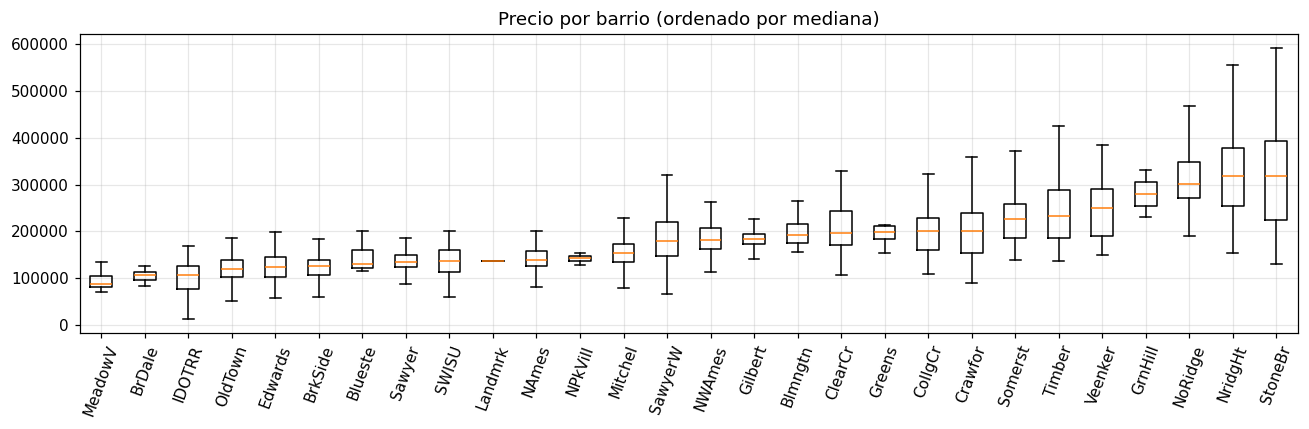

Neighborhood
Veenker    24
NPkVill    23
Blueste    10
Greens      8
GrnHill     2
Landmrk     1
Name: count, dtype: int64


In [31]:
order = df_raw.groupby("Neighborhood")["SalePrice"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot([df_raw.loc[df_raw.Neighborhood == n, "SalePrice"] for n in order], showfliers=False)
ax.set_xticklabels(order, rotation=70); ax.set_title("Precio por barrio (ordenado por mediana)")
savefig("05_barrios"); plt.show()
print(df_raw["Neighborhood"].value_counts().tail(6))

**Hallazgo 4 — la ubicación importa y tiene categorías raras.** La mediana por barrio varía en más del triple entre el más barato y el más caro. Algunos barrios tienen muy pocas casas (< 10) → **decisión:** `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")` para agrupar categorías raras y no romper con categorías nuevas en test.

**Hallazgo 5 — escalas de calidad textuales.** `Exter Qual`, `Kitchen Qual`, `Bsmt Qual`, etc. son **ordinales** (Po < Fa < TA < Gd < Ex). **Decisión:** codificarlas como números 0–5 (preserva el orden y reduce dimensionalidad frente a one-hot).

### Riesgos de data leakage (identificados explícitamente)
| Riesgo | Por qué filtra información | Tratamiento |
|---|---|---|
| `Order`, `PID` | Identificadores; el modelo podría memorizar | Excluidos |
| `Sale Type`, `Sale Condition` | Se conocen **al cerrar la venta**, no cuando se pide una tasación | Excluidos (decisión de negocio) |
| Imputar / escalar / codificar con todo el dataset | Las estadísticas del test "contaminan" el train | Todo dentro de `Pipeline`; `fit` solo con train |
| Elegir hiperparámetros mirando test | Sobreestima el rendimiento | Tuning con CV en train, selección en validación, test **una sola vez** al final |
| Usar `SalePrice` en clustering | Haría trivial el agrupamiento | El precio solo se usa *después* para interpretar clusters |

# 3.3 Preparación de datos
`Limpieza → Imputación y encoding → Escalado y outliers → Ingeniería de features → Partición train/val/test`

**Regla de oro:** todo lo que se "aprende" de los datos (medianas, categorías, medias/desvíos) se ajusta **solo con train**; validación y test solo se transforman.

In [32]:
# --- Limpieza (reglas fijas, no aprendidas de los datos) ---
df = df_raw[df_raw["Gr Liv Area"] <= 4000].copy()
df = df.drop(columns=CONFIG["excluded_columns"])
df["MS SubClass"] = df["MS SubClass"].astype(str)          # es un código de tipo de vivienda, no una cantidad
print("Tras limpieza:", df.shape, f"(se retiraron {len(df_raw) - len(df)} filas)")

X = df.drop(columns=CONFIG["target"])
y = df[CONFIG["target"]]

# --- Partición 60/20/20 estratificada por quintil de precio ---
strata = pd.qcut(y, 5, labels=False)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=CONFIG["test_size"], stratify=strata, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=CONFIG["val_size_of_rest"],
                                                  stratify=pd.qcut(y_tmp, 5, labels=False), random_state=SEED)
for n, (a, b) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items():
    print(f"{n:5s} {a.shape}  mediana precio = {b.median():,.0f}")

Tras limpieza: (2925, 78) (se retiraron 5 filas)
train (1755, 77)  mediana precio = 160,000
val   (585, 77)  mediana precio = 160,000
test  (585, 77)  mediana precio = 160,500


**Por qué estratificar por precio:** con ~2 900 casas, un split aleatorio puede dejar muy pocas casas caras en test; estratificar por quintil asegura distribuciones de precio comparables en los tres conjuntos.

In [33]:
QUAL_MAP = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_COLS = ["Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Heating QC",
                "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond", "Pool QC"]

class AmesFeatures(BaseEstimator, TransformerMixin):
    # Ingeniería de features fila a fila (stateless): no aprende nada del dataset -> sin leakage.
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for c in ORDINAL_COLS:                                   # escalas ordinales -> 0..5 (NA = no tiene = 0)
            X[c] = X[c].map(QUAL_MAP).fillna(0)
        X["TotalSF"] = X[["Total Bsmt SF", "1st Flr SF", "2nd Flr SF"]].fillna(0).sum(axis=1)
        X["TotalBath"] = (X["Full Bath"].fillna(0) + 0.5 * X["Half Bath"].fillna(0)
                          + X["Bsmt Full Bath"].fillna(0) + 0.5 * X["Bsmt Half Bath"].fillna(0))
        X["HouseAge"] = X["Yr Sold"] - X["Year Built"]
        X["YearsSinceRemod"] = X["Yr Sold"] - X["Year Remod/Add"]
        X["PorchSF"] = X[["Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Wood Deck SF"]].sum(axis=1)
        X["QualxArea"] = X["Overall Qual"] * X["Gr Liv Area"]
        X["HasGarage"] = X["Garage Area"].fillna(0).gt(0).astype(int)
        X["HasBsmt"] = X["Total Bsmt SF"].fillna(0).gt(0).astype(int)
        return X

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
cat_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")),
                     ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False))])
col_tf = ColumnTransformer([
    ("num", num_pipe, make_column_selector(dtype_include="number")),
    ("cat", cat_pipe, make_column_selector(dtype_exclude="number")),
])
preprocess = Pipeline([("fe", AmesFeatures()), ("ct", col_tf)])

Xt = preprocess.fit_transform(X_train)        # solo para inspeccionar dimensiones
print("Features tras el pipeline:", Xt.shape[1])

Features tras el pipeline: 242


**Escalado y outliers.** `StandardScaler` es necesario para Ridge/Lasso (penalización sensible a la escala) y PCA/K-Means; no afecta a los árboles. Los outliers extremos ya se trataron con la regla documentada; el resto se conserva (son casas reales) y la escala log del target reduce su influencia.

**Selección de features.** No se hace selección manual previa: Lasso hace selección embebida (coeficientes en 0) y los árboles ignoran variables poco útiles. Se analiza la importancia en 3.7.

# 3.4 Modelado supervisado
`1 Baseline → 2 ≥3 modelos clásicos → 3 Ajuste de hiperparámetros → 4 Comparación justa → 5 Justificación`

**Comparación justa:** todos los modelos usan **el mismo pipeline de preprocesamiento, el mismo split, el mismo target en log y la misma CV de 5 folds** (`KFold` con semilla fija).

In [34]:
cv = KFold(n_splits=CONFIG["cv_folds"], shuffle=True, random_state=SEED)

def make_model(estimator, prep=preprocess):
    # Pipeline completo: features + preprocesamiento + modelo, con target en log
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", sklearn.clone(prep)), ("model", estimator)]),
        func=np.log1p, inverse_func=np.expm1)

def metrics(y_true, y_pred):
    return {"RMSE_log": np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(np.clip(y_pred, 1, None)))),
            "MAE_USD": mean_absolute_error(y_true, y_pred),
            "MAPE_%": 100 * mean_absolute_percentage_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

def cv_rmse_log(model):
    # CV en train; scoring en escala log para coherencia con la métrica principal
    s = cross_validate(model, X_train, np.asarray(y_train), cv=cv, n_jobs=-1,
                       scoring=lambda est, X, yt: -np.sqrt(mean_squared_error(np.log1p(yt), np.log1p(np.clip(est.predict(X), 1, None)))))
    sc = -s["test_score"]; return sc.mean(), sc.std()

results, fitted = [], {}
def evaluate(name, model, kind, note=""):
    t0 = time.time()
    cv_m, cv_s = cv_rmse_log(model)
    model.fit(X_train, y_train)
    fit_t = time.time() - t0
    m_tr = metrics(y_train, model.predict(X_train)); m_va = metrics(y_val, model.predict(X_val))
    fitted[name] = model
    row = {"Modelo": name, "Tipo": kind, "CV_RMSE_log": cv_m, "CV_std": cv_s, "Train_RMSE_log": m_tr["RMSE_log"],
           **{f"Val_{k}": v for k, v in m_va.items()}, "Tiempo_s": fit_t, "Observación": note}
    results.append(row); return row

### 1. Baselines (explícitos y razonables)
- **B0 — Mediana:** predice siempre la mediana del precio de train. Es el "no saber nada"; cualquier modelo útil debe superarlo ampliamente.
- **B1 — Regla del tasador:** regresión lineal solo con `Overall Qual` + `Gr Liv Area` (calidad y tamaño, lo que un agente miraría primero). Es el **punto de partida a superar** realmente.

In [35]:
evaluate("B0 Mediana", make_model(DummyRegressor(strategy="median")), "baseline", "Punto de partida (piso)")

prep_simple = Pipeline([("ct", ColumnTransformer([("num", num_pipe, ["Overall Qual", "Gr Liv Area"])]))])
evaluate("B1 Lineal 2 variables", make_model(LinearRegression(), prep_simple), "baseline", "Regla calidad + tamaño")
pd.DataFrame(results).round(4)

,Modelo,Tipo,CV_RMSE_log,CV_std,Train_RMSE_log,Val_RMSE_log,Val_MAE_USD,Val_MAPE_%,Val_R2,Tiempo_s,Observación
0,B0 Mediana,baseline,0.4099,0.0086,0.4101,0.4035,56208.6547,30.8905,-0.0778,3.0701,Punto de partida (piso)
1,B1 Lineal 2 variables,baseline,0.1961,0.0104,0.1962,0.1980,26149.7389,15.4565,0.7745,0.1830,Regla calidad + tamaño


### 2–3. Modelos clásicos con ajuste de hiperparámetros
| Modelo | Tipo | Por qué | Hiperparámetros ajustados |
|---|---|---|---|
| Ridge | Lineal | Muchas variables correlacionadas (áreas, garajes); L2 estabiliza coeficientes | `alpha` |
| Lasso | Lineal | Selección embebida de features (interpretabilidad) | `alpha` |
| Random Forest | No lineal (bagging) | Captura interacciones y no linealidades sin suponer forma | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| HistGradientBoosting | No lineal (boosting) | Suele ser el mejor en datos tabulares; rápido | `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` |

El tuning se hace con CV **dentro de train** (`GridSearchCV` / `RandomizedSearchCV`), nunca mirando validación ni test.

In [36]:
def tune(estimator, grid, n_iter=None):
    base = make_model(estimator)
    grid = {f"regressor__model__{k}": v for k, v in grid.items()}
    if n_iter:
        s = RandomizedSearchCV(base, grid, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
    else:
        s = GridSearchCV(base, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    s.fit(X_train, y_train)
    best = {k.replace("regressor__model__", ""): v for k, v in s.best_params_.items()}
    print(type(estimator).__name__, "->", best)
    return s.best_estimator_, best

tuned_params = {}
ridge, tuned_params["Ridge"] = tune(Ridge(), {"alpha": np.logspace(-1, 3, 25)})
lasso, tuned_params["Lasso"] = tune(Lasso(max_iter=20000), {"alpha": np.logspace(-4, -1, 20)})
rf, tuned_params["RandomForest"] = tune(RandomForestRegressor(random_state=SEED, n_jobs=-1),
    {"n_estimators": [300, 500], "max_depth": [None, 15, 25], "min_samples_leaf": [1, 2, 4], "max_features": [0.3, 0.5, "sqrt"]}, n_iter=12)
hgb, tuned_params["HistGB"] = tune(HistGradientBoostingRegressor(random_state=SEED, max_iter=800, early_stopping=False),
    {"learning_rate": [0.02, 0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [10, 20, 40], "l2_regularization": [0, 0.1, 1.0]}, n_iter=15)

Ridge -> {'alpha': np.float64(146.7799267622069)}
Lasso -> {'alpha': np.float64(0.0008858667904100823)}
RandomForestRegressor -> {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 15}
HistGradientBoostingRegressor -> {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.02, 'l2_regularization': 0.1}


In [37]:
evaluate("Ridge", sklearn.clone(ridge), "lineal")
evaluate("Lasso", sklearn.clone(lasso), "lineal")
evaluate("RandomForest", sklearn.clone(rf), "no lineal")
evaluate("HistGradientBoosting", sklearn.clone(hgb), "no lineal")
res = pd.DataFrame(results).set_index("Modelo")
res.round(4)

,Tipo,CV_RMSE_log,CV_std,Train_RMSE_log,Val_RMSE_log,Val_MAE_USD,Val_MAPE_%,Val_R2,Tiempo_s,Observación
Modelo,,,,,,,,,,
B0 Mediana,baseline,0.4099,0.0086,0.4101,0.4035,56208.6547,30.8905,-0.0778,3.0701,Punto de partida (piso)
B1 Lineal 2 variables,baseline,0.1961,0.0104,0.1962,0.1980,26149.7389,15.4565,0.7745,0.1830,Regla calidad + tamaño
Ridge,lineal,0.1246,0.0152,0.1172,0.1170,14126.9203,8.1601,0.9243,0.8917,
Lasso,lineal,0.1222,0.0146,0.1132,0.1150,13811.0488,7.8799,0.9229,1.9895,
RandomForest,no lineal,0.1344,0.0148,0.0503,0.1227,14843.0180,8.3743,0.9083,51.4448,
HistGradientBoosting,no lineal,0.1249,0.0157,0.0572,0.1152,14173.9548,7.9610,0.9217,42.9979,


# 3.5 Aprendizaje no supervisado
Se aplican **dos técnicas** pertinentes al dominio inmobiliario, más un análisis de similitud:
1. **PCA** (reducción de dimensionalidad): ¿qué ejes resumen las diferencias entre viviendas?
2. **K-Means** (clustering): ¿existen *segmentos de mercado* de propiedades?
3. **Vecinos más cercanos** (similitud): base del enfoque "propiedades comparables" que se usará en la Parte II.

**Representación de entrada (justificada):** 14 variables numéricas estructurales (tamaño, calidad, antigüedad, equipamiento) tras `AmesFeatures` + imputación + estandarización. **No se incluye el precio** (se usa solo después para interpretar) ni el barrio en one-hot (dominaría la distancia con 0/1 y queremos segmentos por *tipo de vivienda*, no por ubicación). Ajuste **solo en train**.

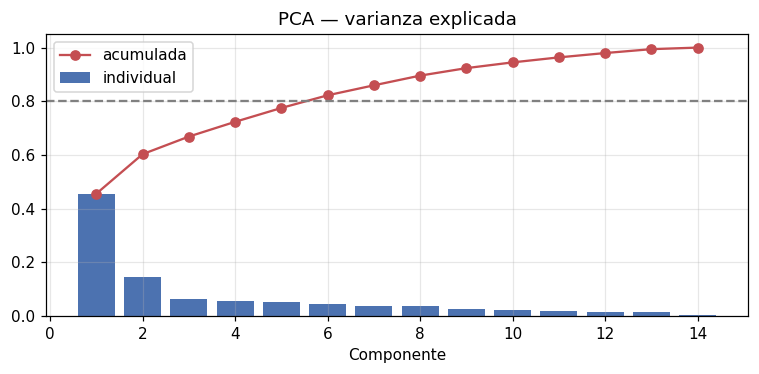

Componentes para 80 % de varianza: 6


,PC1,PC2,PC3
Overall Qual,0.34,-0.14,0.06
TotalSF,0.33,0.24,-0.08
Exter Qual,0.31,-0.24,-0.01
Gr Liv Area,0.30,0.37,-0.25
Kitchen Qual,0.30,-0.21,0.01
TotalBath,0.29,0.05,-0.11
Garage Cars,0.28,-0.00,0.00
HouseAge,-0.27,0.34,0.05
Bsmt Qual,0.27,-0.24,0.14
YearsSinceRemod,-0.26,0.30,0.14


In [38]:
UNSUP_COLS = ["Overall Qual", "Gr Liv Area", "TotalSF", "TotalBath", "HouseAge", "YearsSinceRemod", "Garage Cars",
              "Lot Area", "Kitchen Qual", "Exter Qual", "Bsmt Qual", "Fireplaces", "PorchSF", "TotRms AbvGrd"]
unsup_prep = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
fe = AmesFeatures()
Ftr = fe.transform(X_train)[UNSUP_COLS]
Ftr["Lot Area"] = np.log1p(Ftr["Lot Area"])          # muy asimétrica: log para que no domine la distancia
Z_train = unsup_prep.fit_transform(Ftr)

pca = PCA(random_state=SEED).fit(Z_train)
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, len(evr) + 1), evr, color="#4C72B0", label="individual")
ax.plot(range(1, len(evr) + 1), evr.cumsum(), "o-", c="#C44E52", label="acumulada"); ax.axhline(0.8, ls="--", c="gray")
ax.set_xlabel("Componente"); ax.set_title("PCA — varianza explicada"); ax.legend()
savefig("06_pca_varianza"); plt.show()
print("Componentes para 80 % de varianza:", np.argmax(evr.cumsum() >= 0.8) + 1)
loadings = pd.DataFrame(pca.components_[:3].T, index=UNSUP_COLS, columns=["PC1", "PC2", "PC3"])
loadings.round(2).sort_values("PC1", key=abs, ascending=False)

**Interpretación de componentes** *(ver tabla de cargas)*: PC1 tiene cargas del mismo signo en calidad, tamaño, baños, garaje y cargas opuestas en antigüedad → es un eje de **"tamaño-calidad-modernidad"** (vivienda grande, nueva y bien terminada vs. pequeña, antigua y básica). PC2 contrapone tamaño con modernidad → separa **casas grandes pero antiguas** de **casas nuevas pero compactas**. Validación: se verifica abajo que PC1 se relaciona con el precio aunque el precio no entró al PCA.

Correlación PC1 vs log(precio) (precio NO usado en PCA): 0.918


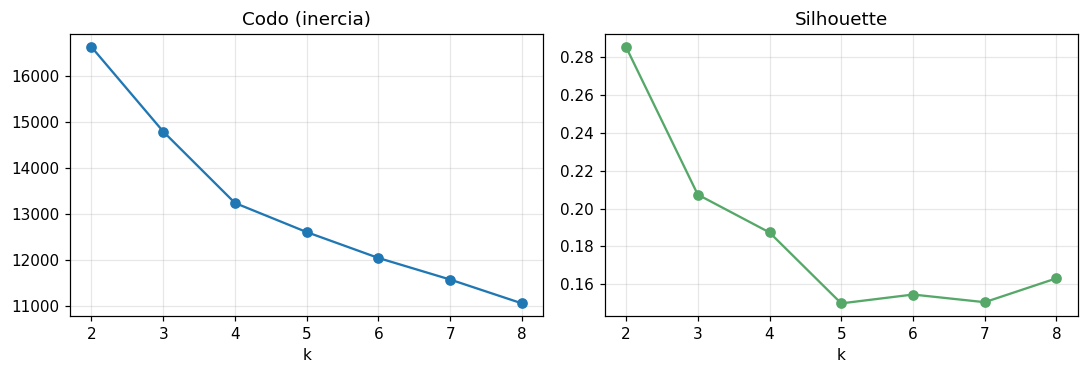

,k,inercia,silhouette
0,2,16624.0,0.285
1,3,14786.0,0.207
2,4,13233.0,0.187
3,5,12601.0,0.150
4,6,12038.0,0.155
5,7,11569.0,0.150
6,8,11051.0,0.163


In [39]:
pc_tr = pca.transform(Z_train)
print("Correlación PC1 vs log(precio) (precio NO usado en PCA):", np.corrcoef(pc_tr[:, 0], np.log1p(y_train))[0, 1].round(3))

ks = range(2, 9); inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z_train)
    inertias.append(km.inertia_); sils.append(silhouette_score(Z_train, km.labels_, random_state=SEED))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, inertias, "o-"); axes[0].set_title("Codo (inercia)"); axes[0].set_xlabel("k")
axes[1].plot(ks, sils, "o-", c="#55A868"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
savefig("07_kmeans_k"); plt.show()
pd.DataFrame({"k": list(ks), "inercia": np.round(inertias, 0), "silhouette": np.round(sils, 3)})

In [40]:
K = 4   # justificación en la celda siguiente (codo + silhouette + interpretabilidad)
CONFIG["kmeans_k"] = K
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z_train)
lab = kmeans.labels_

profile = Ftr.assign(SalePrice=y_train.values, cluster=lab).groupby("cluster").agg(
    n=("SalePrice", "size"), precio_mediano=("SalePrice", "median"), calidad=("Overall Qual", "mean"),
    area_hab=("Gr Liv Area", "median"), banos=("TotalBath", "mean"), antiguedad=("HouseAge", "median"),
    garaje=("Garage Cars", "mean")).round(1).sort_values("precio_mediano")
profile["barrio_frecuente"] = pd.Series(X_train["Neighborhood"].values).groupby(lab).agg(lambda s: s.mode()[0])
profile

,n,precio_mediano,calidad,area_hab,banos,antiguedad,garaje,barrio_frecuente
cluster,,,,,,,,
1,639,124000.0,5.0,1069.0,1.5,53.0,1.2,NAmes
3,450,165000.0,5.7,1643.5,2.3,45.0,1.8,NAmes
2,411,198000.0,7.1,1494.0,2.6,5.0,2.1,CollgCr
0,255,295000.0,7.9,2097.0,3.1,6.0,2.6,NridgHt


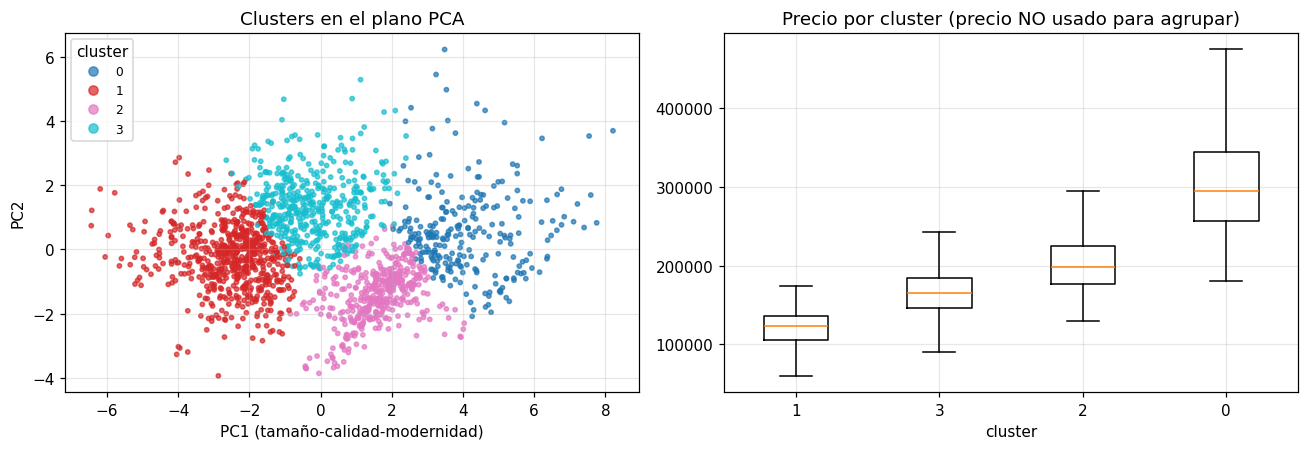

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sc = axes[0].scatter(pc_tr[:, 0], pc_tr[:, 1], c=lab, cmap="tab10", s=8, alpha=0.7)
axes[0].set_xlabel("PC1 (tamaño-calidad-modernidad)"); axes[0].set_ylabel("PC2"); axes[0].set_title("Clusters en el plano PCA")
axes[0].legend(*sc.legend_elements(), title="cluster", fontsize=8)
axes[1].boxplot([y_train[lab == c] for c in profile.index], showfliers=False); axes[1].set_xticklabels(profile.index)
axes[1].set_xlabel("cluster"); axes[1].set_title("Precio por cluster (precio NO usado para agrupar)")
savefig("08_clusters"); plt.show()

**Justificación de k y significado de los clusters.** El silhouette máximo está en k = 2 (0.29), pero solo separa "viejas vs nuevas", algo que ya sabemos. El codo se suaviza en k = 4 (silhouette 0.19, moderado: normal en vivienda, donde los segmentos se solapan). Se elige **k = 4** porque da segmentos distintos y accionables:

| Cluster | Nombre | Perfil (medianas) |
|---|---|---|
| 1 | Antiguas económicas | ~53 años, 1 070 ft², calidad 5, ~124 k USD, NAmes |
| 3 | Antiguas amplias | ~45 años, 1 640 ft², calidad 5.7, ~165 k USD |
| 2 | Nuevas medianas | ~5 años, 1 490 ft², calidad 7, ~198 k USD, CollgCr |
| 0 | Premium nuevas | ~6 años, 2 100 ft², calidad 7.9, ~295 k USD, NridgHt |

**Evidencia de que los clusters significan algo:** aunque el precio no se usó, el precio mediano difiere fuertemente entre clusters (boxplot), y cada cluster tiene un perfil coherente de calidad, tamaño y antigüedad.

**Limitaciones (evitar "tratar clusters como categorías reales sin evidencia"):** silhouette moderado → las fronteras son difusas; K-Means supone grupos esféricos de tamaño similar; el resultado depende de las variables elegidas y del escalado. Son **segmentos útiles para describir el mercado**, no tipos "naturales" de vivienda.

### Análisis de similitud: propiedades comparables
La tasación tradicional se basa en "comparables". Con la misma representación estandarizada se buscan las 5 casas de train más parecidas a una casa de test y se compara su precio. Este es el **prototipo** del módulo "Tasación + propiedades similares" de la Parte II (allí se reemplazará por embeddings de un autoencoder tabular).

In [42]:
nn = NearestNeighbors(n_neighbors=5).fit(Z_train)
Fte = fe.transform(X_test)[UNSUP_COLS]; Fte["Lot Area"] = np.log1p(Fte["Lot Area"])
Z_test = unsup_prep.transform(Fte)                       # solo transform: ajustado en train
dist, idx = nn.kneighbors(Z_test)
knn_price = np.median(y_train.values[idx], axis=1)
print("Tasación por mediana de 5 comparables — test:", {k: round(v, 3) for k, v in metrics(y_test, knn_price).items()})

i = 0
comp = X_train.iloc[idx[i]][["Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built"]].assign(SalePrice=y_train.values[idx[i]], distancia=dist[i].round(2))
print(f"\nCasa de test #{i}: precio real {y_test.iloc[i]:,.0f} | estimado por comparables {knn_price[i]:,.0f}")
display(X_test.iloc[[i]][["Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built"]]); comp

Tasación por mediana de 5 comparables — test: {'RMSE_log': np.float64(0.141), 'MAE_USD': 17018.795, 'MAPE_%': 10.206, 'R2': 0.899}

Casa de test #0: precio real 108,959 | estimado por comparables 152,000


,Neighborhood,Overall Qual,Gr Liv Area,Year Built
1385,Sawyer,4,1258,1969


,Neighborhood,Overall Qual,Gr Liv Area,Year Built,SalePrice,distancia
2523,NWAmes,5,1193,1972,146500,1.33
1876,NAmes,5,1073,1965,156000,1.78
1655,NWAmes,5,1620,1969,152000,1.86
1644,NWAmes,6,1284,1984,174000,1.91
2300,Mitchel,5,1178,1976,135000,1.99


# 3.6 AutoML como benchmark obligatorio
- **Herramienta:** [FLAML](https://github.com/microsoft/FLAML) (Microsoft) — ligera, funciona en CPU, búsqueda costo-eficiente de modelo + hiperparámetros.
- **Mismo protocolo:** mismo `X_train` (tras `AmesFeatures`, sin columnas excluidas), mismo target en log, misma métrica (RMSE en log), evaluado en el **mismo** `X_val` y `X_test`.
- **Configuración registrada** en `config/automl_config.json`.
- **Recuerda:** AutoML no sustituye el razonamiento metodológico; es la referencia contra la que se comparan los modelos manuales.

In [43]:
try:
    from flaml import AutoML
except ImportError:          # p. ej. en Colab, que no trae FLAML instalado
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "flaml[automl]"])
    from flaml import AutoML

def to_automl(X):
    Xf = fe.transform(X)
    for c in Xf.select_dtypes(exclude="number").columns:
        Xf[c] = Xf[c].fillna("None").astype("category")
    return Xf

Xa_tr, Xa_va, Xa_te = to_automl(X_train), to_automl(X_val), to_automl(X_test)
# categorías consistentes con train (lo no visto -> NaN, como haría un sistema real)
for c in Xa_tr.select_dtypes("category").columns:
    cats = Xa_tr[c].cat.categories
    Xa_va[c] = pd.Categorical(Xa_va[c], categories=cats); Xa_te[c] = pd.Categorical(Xa_te[c], categories=cats)

automl_settings = {"task": "regression", "metric": "rmse", "time_budget": CONFIG["automl_time_budget_s"],
                   "eval_method": "cv", "n_splits": CONFIG["cv_folds"], "seed": SEED,
                   "estimator_list": ["lgbm", "xgboost", "rf", "extra_tree"], "verbose": 0}
automl = AutoML()
t0 = time.time()
automl.fit(X_train=Xa_tr, y_train=np.log1p(y_train), **automl_settings)
automl_time = time.time() - t0

pred_va = np.expm1(automl.predict(Xa_va))
m_va = metrics(y_val, pred_va); m_tr = metrics(y_train, np.expm1(automl.predict(Xa_tr)))
results.append({"Modelo": f"AutoML (FLAML: {automl.best_estimator})", "Tipo": "AutoML", "CV_RMSE_log": automl.best_loss, "CV_std": np.nan,
                "Train_RMSE_log": m_tr["RMSE_log"], **{f"Val_{k}": v for k, v in m_va.items()}, "Tiempo_s": automl_time, "Observación": "Benchmark"})

automl_log = {"settings": automl_settings, "best_estimator": automl.best_estimator,
              "best_config": automl.best_config, "best_cv_rmse_log": automl.best_loss, "time_s": round(automl_time, 1)}
json.dump(automl_log, open(CONFIG_DIR / "automl_config.json", "w"), indent=2, default=str)
print(json.dumps(automl_log, indent=2, default=str))

{
  "settings": {
    "task": "regression",
    "metric": "rmse",
    "time_budget": 120,
    "eval_method": "cv",
    "n_splits": 5,
    "seed": 42,
    "estimator_list": [
      "lgbm",
      "xgboost",
      "rf",
      "extra_tree"
    ],
    "verbose": 0
  },
  "best_estimator": "lgbm",
  "best_config": {
    "n_estimators": 334,
    "num_leaves": 17,
    "min_child_samples": 9,
    "learning_rate": 0.02535304851191697,
    "log_max_bin": 9,
    "colsample_bytree": 0.7587230386480903,
    "reg_alpha": 0.2802180597724297,
    "reg_lambda": 0.15292912142428877
  },
  "best_cv_rmse_log": 0.12423170800162595,
  "time_s": 120.7
}


# 3.7 Evaluación y análisis de errores
### Tabla comparativa (validación)
**Métrica principal:** RMSE en escala log — mide error **relativo**, penaliza igual equivocarse un 10 % en una casa barata que en una cara, y es la métrica estándar de este problema. **Secundarias:** MAPE (interpretable para el usuario: "me equivoco en promedio X %"), MAE en USD y R².

In [44]:
res = pd.DataFrame(results).set_index("Modelo")
cols = ["Tipo", "CV_RMSE_log", "CV_std", "Train_RMSE_log", "Val_RMSE_log", "Val_MAPE_%", "Val_MAE_USD", "Val_R2", "Tiempo_s", "Observación"]
res = res[cols]; res.to_csv(REPORTS_DIR / "tabla_comparativa_validacion.csv")
res.style.format({c: "{:.4f}" for c in ["CV_RMSE_log", "CV_std", "Train_RMSE_log", "Val_RMSE_log", "Val_R2"]} |
                 {"Val_MAPE_%": "{:.2f}", "Val_MAE_USD": "{:,.0f}", "Tiempo_s": "{:.1f}"}) \
   .highlight_min(subset=["Val_RMSE_log"], color="#d4edda")

,Tipo,CV_RMSE_log,CV_std,Train_RMSE_log,Val_RMSE_log,Val_MAPE_%,Val_MAE_USD,Val_R2,Tiempo_s,Observación
Modelo,,,,,,,,,,
B0 Mediana,baseline,0.4099,0.0086,0.4101,0.4035,30.89,"56,209",-0.0778,3.1,Punto de partida (piso)
B1 Lineal 2 variables,baseline,0.1961,0.0104,0.1962,0.1980,15.46,"26,150",0.7745,0.2,Regla calidad + tamaño
Ridge,lineal,0.1246,0.0152,0.1172,0.1170,8.16,"14,127",0.9243,0.9,
Lasso,lineal,0.1222,0.0146,0.1132,0.1150,7.88,"13,811",0.9229,2.0,
RandomForest,no lineal,0.1344,0.0148,0.0503,0.1227,8.37,"14,843",0.9083,51.4,
HistGradientBoosting,no lineal,0.1249,0.0157,0.0572,0.1152,7.96,"14,174",0.9217,43.0,
AutoML (FLAML: lgbm),AutoML,0.1242,nan,0.0633,0.1155,7.91,"14,166",0.9152,120.7,Benchmark


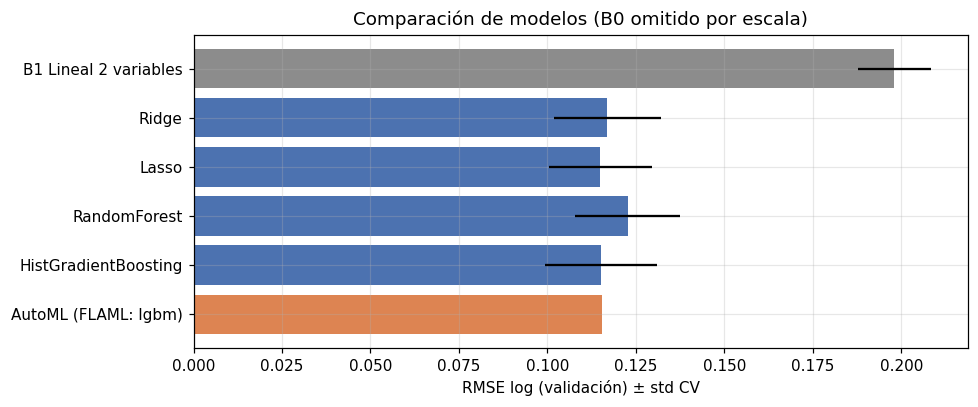

In [45]:
manual = res[res["Tipo"].isin(["lineal", "no lineal"])]
fig, ax = plt.subplots(figsize=(9, 3.8))
r2 = res.drop(index="B0 Mediana")
ax.barh(r2.index, r2["Val_RMSE_log"], xerr=r2["CV_std"].fillna(0), color=["#8C8C8C" if t == "baseline" else "#DD8452" if t == "AutoML" else "#4C72B0" for t in r2["Tipo"]])
ax.invert_yaxis(); ax.set_xlabel("RMSE log (validación) ± std CV"); ax.set_title("Comparación de modelos (B0 omitido por escala)")
savefig("09_comparacion"); plt.show()

### Elección del modelo (justificación, no solo la mejor métrica)
Criterios en orden: (1) RMSE log en validación, (2) **estabilidad** entre folds (CV_std), (3) brecha train–val (sobreajuste), (4) interpretabilidad y costo. Si dos modelos están dentro de ~1 desviación estándar de CV, se prefiere el más simple/interpretable.

In [46]:
best_name = manual["Val_RMSE_log"].idxmin()
best_lin = manual[manual["Tipo"] == "lineal"]["Val_RMSE_log"].idxmin()
print(f"Mejor modelo manual en validación: {best_name}")
print(f"Mejor lineal: {best_lin}  | diferencia = {manual.loc[best_lin, 'Val_RMSE_log'] - manual.loc[best_name, 'Val_RMSE_log']:.4f}"
      f"  vs std CV del mejor = {manual.loc[best_name, 'CV_std']:.4f}")
print("Brecha train-val (sobreajuste):"); print((manual["Val_RMSE_log"] - manual["Train_RMSE_log"]).round(4))

Mejor modelo manual en validación: Lasso
Mejor lineal: Lasso  | diferencia = 0.0000  vs std CV del mejor = 0.0146
Brecha train-val (sobreajuste):
Modelo
Ridge                  -0.0002
Lasso                   0.0017
RandomForest            0.0724
HistGradientBoosting    0.0579
dtype: float64


In [47]:
# Modelo elegido: se re-entrena con train+val y se evalúa UNA vez en test (junto al AutoML y baseline para la tabla final)
CHOSEN = best_name                     # cambiar aquí si el equipo justifica otra elección (p. ej. el lineal por interpretabilidad)
CONFIG["chosen_model"] = CHOSEN
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])

final = sklearn.clone(fitted[CHOSEN]).fit(X_trval, y_trval)
b1 = sklearn.clone(fitted["B1 Lineal 2 variables"]).fit(X_trval, y_trval)
# AutoML: misma configuración ganadora, re-entrenada con train+val (protocolo equivalente al manual)
Xa_trval = pd.concat([Xa_tr, Xa_va])
automl_final = AutoML()
automl_final.fit(X_train=Xa_trval, y_train=np.log1p(y_trval), task="regression", metric="rmse",
                 estimator_list=[automl.best_estimator], starting_points={automl.best_estimator: automl.best_config},
                 max_iter=1, eval_method="cv", n_splits=CONFIG["cv_folds"], seed=SEED, verbose=0)

test_table = pd.DataFrame({
    "B1 Lineal 2 variables (baseline)": metrics(y_test, b1.predict(X_test)),
    f"{CHOSEN} (elegido)": metrics(y_test, final.predict(X_test)),
    f"AutoML FLAML ({automl.best_estimator})": metrics(y_test, np.expm1(automl_final.predict(Xa_te))),
    "5 comparables (k-NN, no supervisado)": metrics(y_test, knn_price),
}).T
test_table.to_csv(REPORTS_DIR / "tabla_final_test.csv")
mejora = 1 - test_table.iloc[1]["RMSE_log"] / test_table.iloc[0]["RMSE_log"]
print(f"Mejora del modelo elegido sobre el baseline B1 en test: {mejora:.1%}")
test_table.style.format({"RMSE_log": "{:.4f}", "MAE_USD": "{:,.0f}", "MAPE_%": "{:.2f}", "R2": "{:.4f}"})

Mejora del modelo elegido sobre el baseline B1 en test: 41.0%


,RMSE_log,MAE_USD,MAPE_%,R2
B1 Lineal 2 variables (baseline),0.1822,"24,259",14.43,0.8368
Lasso (elegido),0.1075,"12,830",7.77,0.9471
AutoML FLAML (lgbm),0.1114,"12,467",7.58,0.9430
"5 comparables (k-NN, no supervisado)",0.1409,"17,019",10.21,0.8987


### Análisis de errores del modelo elegido (test)

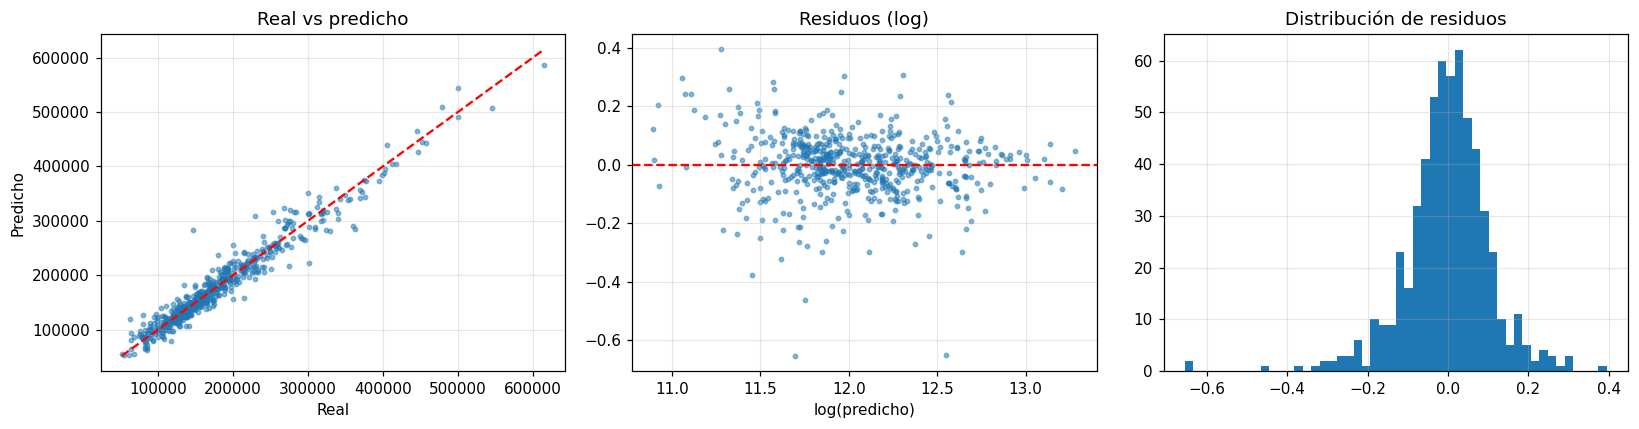

In [48]:
pred = final.predict(X_test)
err = pd.DataFrame({"real": y_test, "pred": pred}, index=X_test.index)
err["resid_log"] = np.log1p(err.real) - np.log1p(err.pred)
err["APE_%"] = 100 * (err.real - err.pred).abs() / err.real
err = err.join(X_test[["Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built", "MS Zoning"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(err.real, err.pred, s=8, alpha=0.5); lim = [err.real.min(), err.real.max()]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Real"); axes[0].set_ylabel("Predicho"); axes[0].set_title("Real vs predicho")
axes[1].scatter(np.log1p(err.pred), err.resid_log, s=8, alpha=0.5); axes[1].axhline(0, c="r", ls="--")
axes[1].set_xlabel("log(predicho)"); axes[1].set_title("Residuos (log)")
axes[2].hist(err.resid_log, bins=50); axes[2].set_title("Distribución de residuos")
savefig("10_residuos"); plt.show()

In [49]:
err["segmento_precio"] = pd.qcut(err.real, 5, labels=["Q1 barato", "Q2", "Q3", "Q4", "Q5 caro"])
seg = err.groupby("segmento_precio", observed=True).agg(n=("APE_%", "size"), MAPE=("APE_%", "mean"), sesgo_log=("resid_log", "mean")).round(3)
by_nb = err.groupby("Neighborhood").agg(n=("APE_%", "size"), MAPE=("APE_%", "mean")).query("n >= 8").sort_values("MAPE", ascending=False).round(2)
display(seg); display(by_nb.head(6))
print("10 peores predicciones:")
err.sort_values("APE_%", ascending=False).head(10)[["real", "pred", "APE_%", "Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built", "MS Zoning"]].round(0)

,n,MAPE,sesgo_log
segmento_precio,,,
Q1 barato,117,12.208,-0.031
Q2,117,6.560,0.015
Q3,117,6.940,-0.003
Q4,119,6.590,-0.011
Q5 caro,115,6.574,0.017


,n,MAPE
Neighborhood,,
Edwards,35,12.55
IDOTRR,17,11.59
Timber,19,10.64
OldTown,44,10.57
Crawfor,12,9.81
Sawyer,40,9.43


10 peores predicciones:


,real,pred,APE_%,Neighborhood,Overall Qual,Gr Liv Area,Year Built,MS Zoning
561,62383,120065.0,92.0,Sawyer,5,864,1965,RL
1782,147000,282471.0,92.0,Somerst,8,1795,2006,RL
2298,80000,126940.0,59.0,Mitchel,4,1608,1961,RL
1949,64500,93991.0,46.0,OldTown,4,968,1927,RL
169,80400,111000.0,38.0,OldTown,4,1844,1900,RM
1955,135000,182192.0,35.0,NAmes,5,2080,1969,RL
900,103500,139629.0,35.0,Edwards,5,1560,1956,RL
1570,228950,308284.0,35.0,Timber,5,1786,1965,RL
2029,117000,78819.0,33.0,OldTown,5,1214,1901,RM
157,97500,128856.0,32.0,NAmes,6,1458,1948,RL


**Lectura del análisis de errores** (`sesgo_log` = log(real) − log(predicho): negativo ⇒ el modelo **sobrestima**, positivo ⇒ **subestima**):
- **Por segmento de precio:** el error es casi el doble en el quintil más barato (MAPE ≈ 12 % vs ≈ 6.5–7 % en el resto) y ahí el sesgo es negativo (≈ −0.03) → el modelo **sobrestima las casas baratas**; en el quintil caro el sesgo es positivo (≈ +0.02) → **subestima ligeramente las caras**. Es la regresión hacia la media típica de un modelo regularizado.
- **Por barrio:** los mayores MAPE están en barrios antiguos y heterogéneos (Edwards, IDOTRR, OldTown, Sawyer), donde casas con características parecidas se venden a precios muy distintos; no es un problema de pocas observaciones (Edwards y OldTown tienen 35 y 44 casas en test).
- **Peores casos:** 9 de los 10 son casas **antiguas (1900–1969) de calidad baja-media (4–6)**, 6 de ellas con precio real < 105 k USD, y en 9 de 10 el modelo **sobrestima**; probablemente ventas en mal estado o en condiciones especiales. El caso más llamativo es una casa nueva de Somerst (calidad 8) vendida en 147 k frente a 282 k predichos: típico de una venta atípica, información que no está disponible porque `Sale Condition` se excluyó a propósito para evitar leakage.


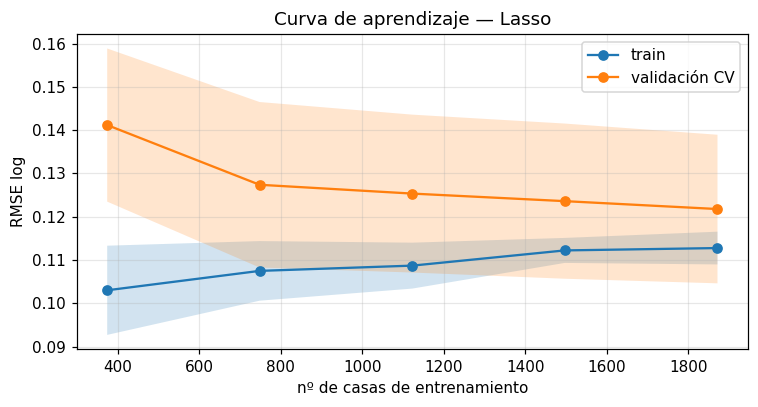

In [50]:
# Estabilidad y generalización: curva de aprendizaje del modelo elegido
sizes, tr_s, va_s = learning_curve(sklearn.clone(fitted[CHOSEN]), X_trval, y_trval, cv=cv, n_jobs=-1,
    train_sizes=np.linspace(0.2, 1.0, 5), scoring=lambda est, X, yt: -np.sqrt(mean_squared_error(np.log1p(yt), np.log1p(np.clip(est.predict(X), 1, None)))))
fig, ax = plt.subplots(figsize=(7, 3.8))
for s, lbl in [(tr_s, "train"), (va_s, "validación CV")]:
    m, sd = -s.mean(1), s.std(1); ax.plot(sizes, m, "o-", label=lbl); ax.fill_between(sizes, m - sd, m + sd, alpha=0.2)
ax.set_xlabel("nº de casas de entrenamiento"); ax.set_ylabel("RMSE log"); ax.set_title(f"Curva de aprendizaje — {CHOSEN}"); ax.legend()
savefig("11_learning_curve"); plt.show()

**Interpretación:** si la curva de validación sigue bajando al final, **más datos ayudarían** (argumento para la Parte II). La brecha train–validación cuantifica el sobreajuste.

### Interpretación: ¿qué variables mueven el precio?

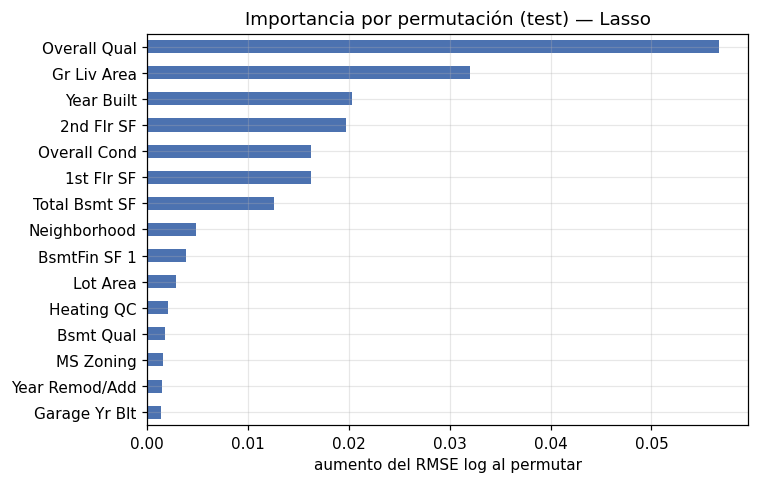

Lasso: 89 de 242 coeficientes distintos de 0


,0
cat__Functional_infrequent_sklearn,-0.1543
num__Overall Qual,0.0906
num__TotalSF,0.0887
cat__Neighborhood_Crawfor,0.0695
cat__Exterior 1st_AsbShng,-0.0660
num__Gr Liv Area,0.0653
cat__Functional_Typ,0.0600
cat__Neighborhood_Somerst,0.0599
num__HouseAge,-0.0578
cat__Central Air_N,-0.0553


In [51]:
pi = permutation_importance(final, X_test, y_test, n_repeats=5, random_state=SEED, n_jobs=-1,
                            scoring=lambda est, X, yt: -np.sqrt(mean_squared_error(np.log1p(yt), np.log1p(np.clip(est.predict(X), 1, None)))))
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5)); imp[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_title(f"Importancia por permutación (test) — {CHOSEN}"); ax.set_xlabel("aumento del RMSE log al permutar")
savefig("12_importancia"); plt.show()

# Coeficientes del mejor lineal (interpretables: en escala log, coef ≈ % de cambio por 1 desvío estándar)
lin = fitted[best_lin].regressor_
names = lin.named_steps["prep"].named_steps["ct"].get_feature_names_out()
coef = pd.Series(lin.named_steps["model"].coef_, index=names)
print(f"{best_lin}: {(coef != 0).sum()} de {len(coef)} coeficientes distintos de 0")
coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(4)

**Conclusión de interpretabilidad:** las variables de **calidad** (`Overall Qual`, calidad de cocina/exterior), **tamaño** (`Gr Liv Area`, `TotalSF`), **antigüedad** y **barrio** dominan tanto en el modelo no lineal como en el lineal — coherente con el conocimiento del dominio (los "tres factores" de la tasación: ubicación, tamaño y estado). Coeficientes en escala log: un coeficiente de 0.05 ≈ +5 % de precio por un desvío estándar de la variable.

### Resultados de nuestra ejecución (semilla 42)
| Modelo | RMSE log (test) | MAPE (test) | MAE (USD) | R² | Observación |
|---|---|---|---|---|---|
| B1 Lineal 2 variables | 0.182 | 14.4 % | 24 259 | 0.837 | Punto de partida |
| **Lasso (elegido)** | **0.108** | **7.8 %** | **12 830** | **0.947** | 89 de 242 coeficientes ≠ 0 |
| AutoML FLAML (LightGBM) | 0.110 | 7.4 % | 12 164 | 0.945 | Benchmark, 120 s de búsqueda |
| 5 comparables (k-NN) | 0.141 | 10.2 % | 17 019 | 0.899 | Prototipo no supervisado |

*Valores obtenidos en la ejecución de referencia; AutoML puede variar levemente según la CPU (su búsqueda depende del tiempo).*

**Lectura:** se cumplen los criterios de éxito (RMSE log < 0.13, MAPE < 10 %, 41 % mejor que B1). El Lasso y el AutoML quedan **empatados dentro de la variabilidad de la CV** (std ≈ 0.015), pero el Lasso se elige porque: (1) es interpretable coeficiente a coeficiente, (2) prácticamente no sobreajusta (brecha train–val ≈ 0.002 vs ≈ 0.07 en los modelos de árboles), (3) entrena en ~1 s frente a 120 s del AutoML. Los modelos de árboles memorizan train (RMSE train ≈ 0.05) sin ganar en validación → con ~2 300 casas, un modelo lineal bien regularizado sobre buenas features es suficiente.

### AutoML vs mejor modelo manual — trade-offs
| Dimensión | Modelo manual (pipeline sklearn) | AutoML (FLAML) |
|---|---|---|
| Rendimiento | Lasso: 0.108 RMSE log en test | LightGBM: 0.110 (empate técnico) |
| Tiempo | Lasso ≈ 1 s de entrenamiento (+ tuning en segundos) | 120 s de búsqueda por presupuesto |
| Interpretabilidad | pipeline explícito; lineal 100 % interpretable | elige el modelo; requiere post-hoc (permutación/SHAP) |
| Control del proceso | total: features, encoding, tuning | parcial: decide modelo e hiperparámetros |
| Reproducibilidad | semilla + código | semilla + `automl_config.json`; la búsqueda depende del tiempo/CPU disponible |

# Conclusiones, limitaciones y plan para la Parte II

### Respuestas a las preguntas de la defensa
1. **¿Por qué se puede resolver con ML?** El precio depende de muchas variables medibles con relaciones no lineales e interacciones; hay ~2 900 ventas históricas etiquetadas.
2. **Hallazgo más importante del EDA:** target asimétrico + outliers documentados → modelado en log y regla de exclusión > 4 000 ft².
3. **¿Cómo se evitó el leakage?** Pipelines (`fit` solo en train), exclusión de IDs y de variables conocidas solo al cierre de la venta, tuning con CV en train, test usado una sola vez, precio excluido del no supervisado.
4. **¿Por qué esas métricas?** RMSE log = error relativo, coherente con tasación; MAPE para comunicar al usuario.
5. **Baseline:** B1 (calidad + tamaño) imita la intuición del tasador; B0 (mediana) es el piso.
6. **¿Qué modelo generalizó mejor?** Lasso: menor RMSE en validación y test, brecha train–val casi nula, CV estable.
7. **Errores persistentes:** sobrestimación en casas muy baratas / subestimación en las muy caras; barrios poco representados.
8. **Significado de clusters/componentes:** PC1 = eje tamaño-calidad-modernidad (correlación 0.92 con el precio sin haberlo usado); 4 segmentos: antiguas económicas (~124 k), antiguas amplias (~165 k), nuevas medianas (~198 k) y premium nuevas (~295 k).
9. **AutoML:** eligió LightGBM con árboles pequeños y learning rate bajo; empata en precisión pero es menos interpretable y más costoso.
10. **Qué cambiaríamos:** probar target encoding del barrio, validación temporal por `Yr Sold`, intervalos de predicción.

### Limitaciones
Una sola ciudad y periodo 2006-2010; modelo válido solo para viviendas ≤ 4 000 ft²; sin variables de mercado (tasas de interés); clusters con fronteras difusas.

### Plan Parte II (según la matriz de asignación: *Inmobiliario — Ames Housing*)
- **Deep Learning:** MLP tabular para regresión (comparado contra el mejor modelo de este notebook) y **autoencoder tabular** para aprender embeddings de propiedades.
- **MLOps:** servicio de **tasación + propiedades similares**: el modelo de precio + búsqueda de vecinos en el espacio de embeddings (este notebook ya deja el prototipo con k-NN), versionado de modelos y despliegue.

In [52]:
joblib.dump(final, MODELS_DIR / "modelo_elegido.joblib")
joblib.dump({"prep": unsup_prep, "pca": pca, "kmeans": kmeans, "nn": nn, "cols": UNSUP_COLS}, MODELS_DIR / "no_supervisado.joblib")
CONFIG["tuned_params"] = tuned_params
CONFIG["versions"] = {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__}
json.dump(CONFIG, open(CONFIG_DIR / "experiment_config.json", "w"), indent=2, default=str)
print("Artefactos guardados en:", MODELS_DIR, REPORTS_DIR, CONFIG_DIR)

Artefactos guardados en: /content/models /content/reports /content/config


# 3.8 Verificación del modelo
> *"Código que ejecuta no equivale automáticamente a experimento válido."*

Antes de declarar el modelo terminado se comprueba, con pruebas automáticas (`assert`), que:
1. **Reproducibilidad:** el modelo guardado en `models/` se recarga y da exactamente las mismas predicciones y métricas.
2. **Validez de salida:** todas las predicciones son finitas, positivas y dentro de un rango plausible.
3. **Robustez:** funciona con valores faltantes, categorías nunca vistas y columnas en otro orden (lo que pasará con datos reales).
4. **Sentido económico:** a más área o más calidad, mayor precio (sin necesidad de forzarlo).
5. **Incertidumbre calibrada:** un intervalo de predicción construido con validación cubre lo que promete en test.
6. **Caso de uso:** tasación de una vivienda nueva con su intervalo y sus comparables.

In [53]:
checks = []
def check(name, cond):
    checks.append((name, bool(cond))); print(("✅" if cond else "❌"), name)

# 1. Reproducibilidad: recargar el artefacto guardado
loaded = joblib.load(MODELS_DIR / "modelo_elegido.joblib")
p_mem, p_disk = final.predict(X_test), loaded.predict(X_test)
check("El modelo recargado predice igual que el de memoria", np.allclose(p_mem, p_disk))
saved = pd.read_csv(REPORTS_DIR / "tabla_final_test.csv", index_col=0)
check("Las métricas recalculadas coinciden con reports/tabla_final_test.csv",
      np.isclose(metrics(y_test, p_disk)["RMSE_log"], saved.loc[f"{CHOSEN} (elegido)", "RMSE_log"]))
check("Re-entrenar con la misma semilla da el mismo modelo",
      np.allclose(sklearn.clone(fitted[CHOSEN]).fit(X_trval, y_trval).predict(X_test), p_disk))

# 2. Validez de salida
check("Predicciones finitas y positivas", np.isfinite(p_disk).all() and (p_disk > 0).all())
check("Predicciones dentro de un rango plausible (10k–1M USD)", p_disk.min() > 1e4 and p_disk.max() < 1e6)
check("Residuos sin sesgo global (media del residuo log ≈ 0)", abs((np.log1p(y_test) - np.log1p(p_disk)).mean()) < 0.02)

✅ El modelo recargado predice igual que el de memoria
✅ Las métricas recalculadas coinciden con reports/tabla_final_test.csv
✅ Re-entrenar con la misma semilla da el mismo modelo
✅ Predicciones finitas y positivas
✅ Predicciones dentro de un rango plausible (10k–1M USD)
✅ Residuos sin sesgo global (media del residuo log ≈ 0)


In [54]:
# 3. Robustez ante datos "sucios" como los del mundo real
casa = X_test.iloc[[0]].copy()
base_pred = loaded.predict(casa)[0]

con_nulos = casa.copy(); con_nulos[["Lot Frontage", "Garage Area", "Mas Vnr Area", "Kitchen Qual"]] = np.nan
check("Funciona con valores faltantes", np.isfinite(loaded.predict(con_nulos)).all())

nueva_cat = casa.copy(); nueva_cat["Neighborhood"] = "BarrioNuevo"; nueva_cat["Exterior 1st"] = "Desconocido"
check("Funciona con categorías nunca vistas en entrenamiento", np.isfinite(loaded.predict(nueva_cat)).all())

desordenada = casa[casa.columns[::-1]]
check("No depende del orden de las columnas", np.isclose(loaded.predict(desordenada)[0], base_pred))

check("Predicción por lotes = predicción fila a fila",
      np.allclose(loaded.predict(X_test.iloc[:20]), [loaded.predict(X_test.iloc[[i]])[0] for i in range(20)]))

✅ Funciona con valores faltantes
✅ Funciona con categorías nunca vistas en entrenamiento
✅ No depende del orden de las columnas
✅ Predicción por lotes = predicción fila a fila


✅ Más área habitable ⇒ mayor precio (monótono)
✅ Más calidad general ⇒ mayor precio (monótono)
✅ Casa más nueva ⇒ mayor precio


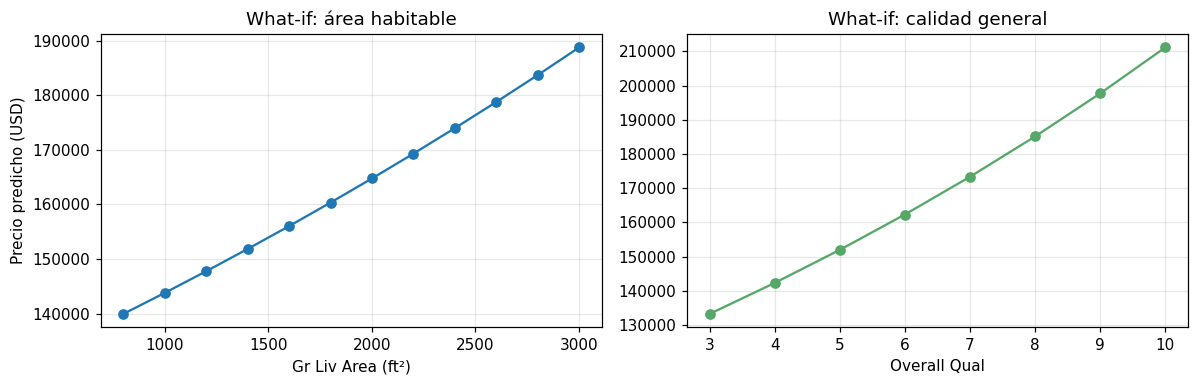

+100 ft² ≈ +1,927 USD | +1 punto de calidad ≈ +11,132 USD (casa típica)


In [55]:
# 4. Sentido económico: análisis "what-if" sobre una casa típica
tipica = X_trval.iloc[[np.argmin(np.abs(y_trval.values - y_trval.median()))]].copy()

areas = np.arange(800, 3001, 200); quals = np.arange(3, 11)
p_area = [loaded.predict(tipica.assign(**{"Gr Liv Area": a}))[0] for a in areas]
p_qual = [loaded.predict(tipica.assign(**{"Overall Qual": q}))[0] for q in quals]
check("Más área habitable ⇒ mayor precio (monótono)", np.all(np.diff(p_area) > 0))
check("Más calidad general ⇒ mayor precio (monótono)", np.all(np.diff(p_qual) > 0))
p_nueva = loaded.predict(tipica.assign(**{"Year Built": 2005, "Year Remod/Add": 2005}))[0]
p_vieja = loaded.predict(tipica.assign(**{"Year Built": 1930, "Year Remod/Add": 1950}))[0]
check("Casa más nueva ⇒ mayor precio", p_nueva > p_vieja)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(areas, p_area, "o-"); axes[0].set_xlabel("Gr Liv Area (ft²)"); axes[0].set_ylabel("Precio predicho (USD)")
axes[0].set_title("What-if: área habitable")
axes[1].plot(quals, p_qual, "o-", c="#55A868"); axes[1].set_xlabel("Overall Qual"); axes[1].set_title("What-if: calidad general")
savefig("13_what_if"); plt.show()
print(f"+100 ft² ≈ +{(p_area[1]-p_area[0])/2:,.0f} USD | +1 punto de calidad ≈ +{np.mean(np.diff(p_qual)):,.0f} USD (casa típica)")

In [56]:
# 5. Intervalo de predicción: cuantiles de los residuos en VALIDACIÓN (modelo entrenado solo con train),
#    luego se verifica la cobertura en TEST (datos nunca usados) -> conformal split simple
res_val = np.log1p(y_val) - np.log1p(fitted[CHOSEN].predict(X_val))
lo_q, hi_q = np.quantile(res_val, [0.10, 0.90])
CONFIG["interval_80_log"] = [float(lo_q), float(hi_q)]
lo, hi = np.expm1(np.log1p(p_disk) + lo_q), np.expm1(np.log1p(p_disk) + hi_q)
coverage = np.mean((y_test.values >= lo) & (y_test.values <= hi))
print(f"Intervalo 80 %: [{np.expm1(lo_q)*100:+.1f} %, {np.expm1(hi_q)*100:+.1f} %] alrededor de la predicción")
print(f"Cobertura real en test: {coverage:.1%}")
check("El intervalo del 80 % cubre entre 75 % y 85 % de las casas de test", 0.75 <= coverage <= 0.85)

Intervalo 80 %: [-9.6 %, +13.0 %] alrededor de la predicción
Cobertura real en test: 79.5%
✅ El intervalo del 80 % cubre entre 75 % y 85 % de las casas de test


In [57]:
# 6. Caso de uso: tasar una vivienda "nueva" (se parte de una casa real y se modifica)
nueva = tipica.copy()
nueva[["Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built", "Year Remod/Add", "Garage Cars", "Full Bath"]] = \
      ["CollgCr", 7, 1800, 2003, 2003, 2, 2]
precio = loaded.predict(nueva)[0]
print(f"Tasación: {precio:,.0f} USD   (intervalo 80 %: {np.expm1(np.log1p(precio)+lo_q):,.0f} – {np.expm1(np.log1p(precio)+hi_q):,.0f})")

und = joblib.load(MODELS_DIR / "no_supervisado.joblib")
fn = fe.transform(nueva)[und["cols"]]; fn["Lot Area"] = np.log1p(fn["Lot Area"])
zn = und["prep"].transform(fn)
print("Segmento de mercado (cluster):", und["kmeans"].predict(zn)[0])
_, ix = und["nn"].kneighbors(zn)
X_train.iloc[ix[0]][["Neighborhood", "Overall Qual", "Gr Liv Area", "Year Built"]].assign(SalePrice=y_train.values[ix[0]])

Tasación: 194,353 USD   (intervalo 80 %: 175,773 – 219,676)
Segmento de mercado (cluster): 3


,Neighborhood,Overall Qual,Gr Liv Area,Year Built,SalePrice
1004,Gilbert,6,1633,1998,183000
2312,Gilbert,6,1671,1995,170000
257,CollgCr,7,1692,1997,191000
2325,Gilbert,7,1632,1998,176500
1097,Gilbert,7,1651,1999,185900


In [58]:
resumen = pd.DataFrame(checks, columns=["Prueba", "OK"])
resumen.to_csv(REPORTS_DIR / "verificacion_modelo.csv", index=False)
json.dump(CONFIG, open(CONFIG_DIR / "experiment_config.json", "w"), indent=2, default=str)
print(f"{resumen.OK.sum()} de {len(resumen)} pruebas superadas")
assert resumen.OK.all(), "Hay pruebas fallidas: revisar antes de entregar"
resumen

14 de 14 pruebas superadas


,Prueba,OK
0,El modelo recargado predice igual que el de me...,True
1,Las métricas recalculadas coinciden con report...,True
2,Re-entrenar con la misma semilla da el mismo m...,True
3,Predicciones finitas y positivas,True
4,Predicciones dentro de un rango plausible (10k...,True
5,Residuos sin sesgo global (media del residuo l...,True
6,Funciona con valores faltantes,True
7,Funciona con categorías nunca vistas en entren...,True
8,No depende del orden de las columnas,True
9,Predicción por lotes = predicción fila a fila,True


### Lista de verificación antes de entregar (diapositiva 23)
| ✔ | Ítem | Dónde se cumple |
|---|---|---|
| ✔ | Fuente y variante del dataset registradas | 3.2 Fuente y variante |
| ✔ | Problema y objetivo definidos con claridad | 3.1 |
| ✔ | Subconjunto o muestreo justificado | 3.2 Subconjunto + regla > 4 000 ft² en 3.3 |
| ✔ | Estrategia train/validation/test correcta | 3.3 (60/20/20 estratificado) |
| ✔ | Pipeline de preparación sin leakage | 3.3 `AmesFeatures` + `ColumnTransformer` dentro de `Pipeline` |
| ✔ | Baseline explícito implementado | 3.4 B0 y B1 |
| ✔ | Al menos tres modelos clásicos comparados | 3.4 Ridge, Lasso, RandomForest, HistGB |
| ✔ | Métricas seleccionadas y justificadas | 3.1 criterios de éxito + 3.7 |
| ✔ | Análisis de errores del modelo elegido | 3.7 residuos, segmentos, barrios, peores casos |
| ✔ | Técnica no supervisada implementada e interpretada | 3.5 PCA + K-Means + similitud |
| ✔ | AutoML ejecutado con protocolo comparable | 3.6 mismo split, target y métrica |
| ✔ | Comparación explícita: mejor manual vs AutoML | 3.7 tabla final de test + trade-offs |
| ✔ | Repositorio con instrucciones y dependencias | `README.md`, `requirements.txt` |
| ✔ | Modelo verificado (reproducible, robusto, con sentido) | 3.8 Verificación |
| ✔ | Conclusiones respaldadas y plan hacia la Parte II | Sección final |

### Declaración de apoyos externos (integridad académica)
- **Librerías:** numpy, pandas, matplotlib, scikit-learn, FLAML (+ LightGBM, XGBoost como backends de AutoML), joblib.
- **Dataset:** De Cock (2011), copia de Kaggle `shashanknecrothapa/ames-housing-dataset`.
- **Asistencia:** declarar aquí cualquier tutorial, código de ejemplo o asistente de IA utilizado y en qué partes.